<a href="https://colab.research.google.com/github/Gizeh-Gutierrez/Maestria_programacion/blob/main/%C3%81rbol_de_Decisi%C3%B3n_para_Regresi%C3%B3n_Objetivo_271752.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

# Cargar dataset
california = fetch_california_housing()

# Convertir a DataFrame
df = pd.DataFrame(california.data, columns=california.feature_names)

# Agregar variable objetivo
df['MedHouseVal'] = california.target

# Mostrar primeras filas
print(df.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [3]:
target = 'MedHouseVal'
print(f"Variable objetivo: {target}")
df.info()
df.describe()

Variable objetivo: MedHouseVal
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


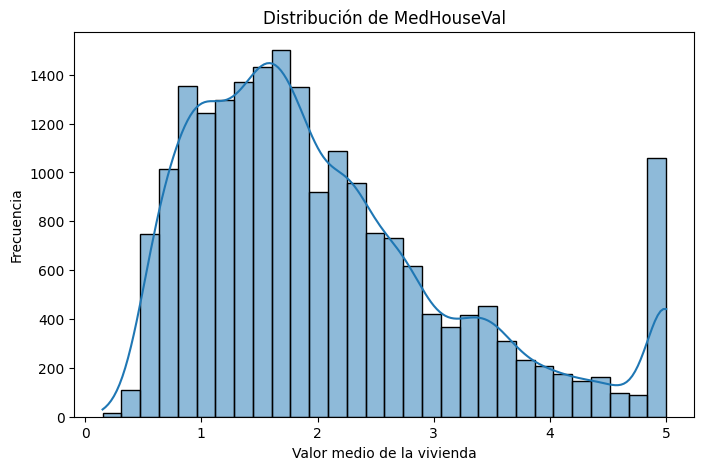

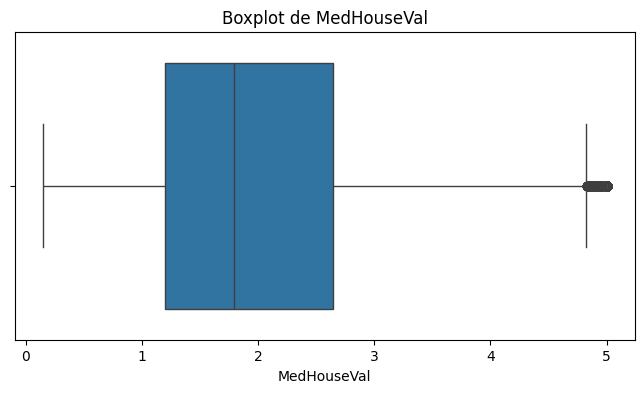

In [4]:
plt.figure(figsize=(8,5))
sns.histplot(df['MedHouseVal'], bins=30, kde=True)
plt.title('Distribución de MedHouseVal')
plt.xlabel('Valor medio de la vivienda')
plt.ylabel('Frecuencia')
plt.show()

plt.figure(figsize=(8,4))
sns.boxplot(x=df['MedHouseVal'])
plt.title('Boxplot de MedHouseVal')
plt.show()

El dataset contiene 20,640 registros y 8 variables predictoras sin valores nulos. La variable objetivo MedHouseVal presenta una distribución asimétrica con algunos valores extremos.

In [5]:
# Variables predictoras
X = df.drop('MedHouseVal', axis=1)

# Variable objetivo
y = df['MedHouseVal']

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (20640, 8)
Dimensiones de y: (20640,)


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Conjunto de entrenamiento:", X_train.shape)
print("Conjunto de prueba:", X_test.shape)

Conjunto de entrenamiento: (16512, 8)
Conjunto de prueba: (4128, 8)


Se utilizaron las 8 variables predictoras como X y MedHouseVal como variable objetivo y. Los datos se dividieron en 80% entrenamiento y 20% prueba para evaluar la capacidad de generalización del modelo, utilizando random_state=42 para asegurar resultados reproducibles.

In [7]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Modelo sin restricciones
tree = DecisionTreeRegressor(
    max_depth=None,
    random_state=42
)

# Entrenamiento
tree.fit(X_train, y_train)

# Predicciones
y_train_pred = tree.predict(X_train)
y_test_pred = tree.predict(X_test)

# Métricas
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

print("RMSE Entrenamiento:", rmse_train)
print("RMSE Prueba:", rmse_test)
print("R² Entrenamiento:", r2_train)
print("R² Prueba:", r2_test)

RMSE Entrenamiento: 3.218325866275131e-16
RMSE Prueba: 0.7037294974840077
R² Entrenamiento: 1.0
R² Prueba: 0.622075845135081


El árbol de decisión sin restricciones obtuvo un ajuste perfecto en entrenamiento (RMSE = 0.00, R² = 1.00), pero su desempeño disminuyó en prueba (RMSE = 0.704, R² = 0.622). Esta diferencia indica que el modelo presenta sobreajuste, ya que memoriza los datos de entrenamiento y no generaliza adecuadamente a datos nuevos.

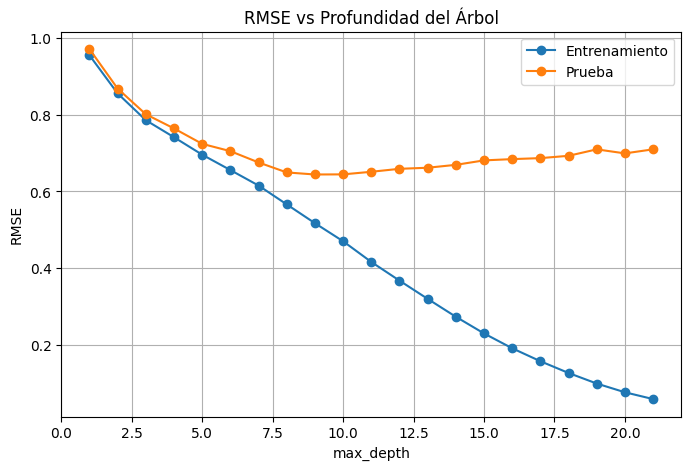

Mejor profundidad: 9
Mejor RMSE de prueba: 0.6443


In [9]:
import matplotlib.pyplot as plt

depths = range(1, 22)

rmse_train = []
rmse_test = []

for d in depths:
    model = DecisionTreeRegressor(
        max_depth=d,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    rmse_train.append(
        np.sqrt(mean_squared_error(y_train, y_train_pred))
    )

    rmse_test.append(
        np.sqrt(mean_squared_error(y_test, y_test_pred))
    )

# Gráfica
plt.figure(figsize=(8,5))
plt.plot(depths, rmse_train, marker='o', label='Entrenamiento')
plt.plot(depths, rmse_test, marker='o', label='Prueba')

plt.xlabel('max_depth')
plt.ylabel('RMSE')
plt.title('RMSE vs Profundidad del Árbol')
plt.legend()
plt.grid(True)
plt.show()

# Mejor profundidad
best_depth = depths[np.argmin(rmse_test)]
best_rmse = min(rmse_test)

print(f"Mejor profundidad: {best_depth}")
print(f"Mejor RMSE de prueba: {best_rmse:.4f}")

La gráfica muestra que el RMSE de entrenamiento disminuye continuamente a medida que aumenta la profundidad del árbol, mientras que el RMSE de prueba disminuye hasta una profundidad de 9 y luego comienza a incrementarse. El mejor desempeño se obtiene con max_depth = 9, alcanzando un RMSE de prueba de 0.6443. A partir de ese punto, el modelo comienza a sobreajustarse, mejorando en entrenamiento pero empeorando en datos no vistos. Por lo tanto, una profundidad de 9 niveles ofrece el mejor equilibrio entre ajuste y capacidad de generalización.

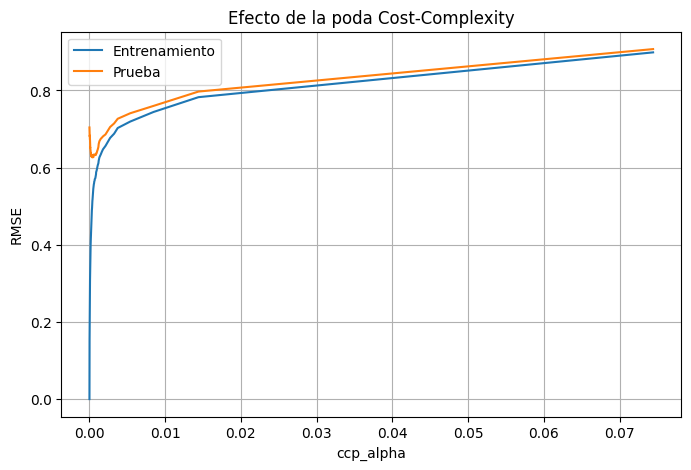

Mejor ccp_alpha: 0.0003689303672913904
Mejor RMSE prueba: 0.626376461879719


In [14]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Obtener valores de poda
path = DecisionTreeRegressor(random_state=42).cost_complexity_pruning_path(
    X_train, y_train
)

ccp_alphas = path.ccp_alphas

# Evaluar cada quinto valor
ccp_alphas = ccp_alphas[::5]

rmse_train = []
rmse_test = []

for alpha in ccp_alphas:
    model = DecisionTreeRegressor(
        random_state=42,
        ccp_alpha=alpha
    )

    model.fit(X_train, y_train)

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    rmse_train.append(
        np.sqrt(mean_squared_error(y_train, pred_train))
    )

    rmse_test.append(
        np.sqrt(mean_squared_error(y_test, pred_test))
    )

# Gráfica
plt.figure(figsize=(8,5))
plt.plot(ccp_alphas, rmse_train, label="Entrenamiento")
plt.plot(ccp_alphas, rmse_test, label="Prueba")

plt.xlabel("ccp_alpha")
plt.ylabel("RMSE")
plt.title("Efecto de la poda Cost-Complexity")
plt.legend()
plt.grid(True)
plt.show()

# Mejor modelo
best_idx = np.argmin(rmse_test)

print("Mejor ccp_alpha:", ccp_alphas[best_idx])
print("Mejor RMSE prueba:", rmse_test[best_idx])

La poda mediante Cost-Complexity Pruning  despues de como 30 minutos tuvo un efecto positivo en la capacidad de generalización del modelo. Primero al aumentar ligeramente ccp_alpha, el RMSE de prueba disminuye, lo que indica una reducción del sobreajuste al eliminar ramas innecesarias del árbol. El mejor resultado se obtuvo con ccp_alpha = 0.000369, alcanzando un RMSE de prueba de 0.6264, que es mejor que el obtenido con el árbol sin poda (RMSE = 0.7037).

A medida que ccp_alpha continúa aumentando, tanto el RMSE de entrenamiento como el de prueba crecen, señal de que el árbol pierde demasiada complejidad y comienza a subajustarse. Por lo que, un valor pequeño de ccp_alpha permite obtener un mejor equilibrio entre complejidad y precisión.

1. Sí. El árbol sin restricciones logró un ajuste perfecto en entrenamiento (RMSE ≈ 0 y R² = 1.0), pero su desempeño en prueba fue mucho menor (RMSE = 0.7037, R² = 0.6221), lo que indica sobreajuste y baja capacidad de generalización.

2. A mayor profundidad, el error de entrenamiento disminuye continuamente. Sin embargo, el error de prueba solo mejora hasta cierto punto y luego aumenta por sobreajuste. La mejor generalización se obtuvo con max_depth = 9 y RMSE = 0.6443.

3. La poda mediante ccp_alpha reduce la complejidad del árbol y el sobreajuste. Esto mejora el desempeño en prueba, aunque valores muy altos de poda generan subajuste y aumentan nuevamente el error.

4. La mejor configuración fue el árbol podado con:
ccp_alpha = 0.00036893
RMSE de prueba = 0.6264
Esta configuración obtuvo el menor error y la mejor capacidad de generalización.


In [15]:

importancias = pd.Series(
    tree.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importancias)

MedInc        0.528509
AveOccup      0.130838
Latitude      0.093717
Longitude     0.082902
AveRooms      0.052975
HouseAge      0.051884
Population    0.030516
AveBedrms     0.028660
dtype: float64
